# Wine — Full Machine Learning Experiment

All figures are saved to `figures/`; tables are saved as CSV. Run from top to bottom.

In [1]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.datasets import load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, adjusted_rand_score, silhouette_score)
from IPython.display import display
SEEDS=[42,52,62]
OUT=Path('figures'); OUT.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
DATASET='wine'
bundle=load_breast_cancer() if DATASET=='breast_cancer' else load_wine()
X=pd.DataFrame(bundle.data,columns=bundle.feature_names)
y=pd.Series(bundle.target,index=X.index,name='target')
CLASS_IDS=np.array(sorted(y.unique()))
CLASS_NAMES=list(bundle.target_names)
LABEL_MAP=dict(zip(CLASS_IDS,CLASS_NAMES))
def savefig(name):
    plt.tight_layout(); plt.savefig(OUT/f'{DATASET}_{name}.png',dpi=160,bbox_inches='tight'); plt.show(); plt.close()
def interpret(message): print('Interpretation:',message)


## 1. Dataset Overview and Class-Label Mapping

In [2]:

print('Dataset:',DATASET,'X shape:',X.shape,'y shape:',y.shape)
display(X.head())
print('Feature names:',list(X.columns))
print('Target labels:',CLASS_IDS.tolist())
print('Target names:',CLASS_NAMES)
print('Label mapping:',LABEL_MAP)
print('Samples per class:'); display(y.value_counts().sort_index().rename(index=LABEL_MAP).to_frame('count'))
assert 'target' not in X.columns and X.index.equals(y.index)
interpret('Features and target are separate. Original scikit-learn class IDs are preserved; breast cancer 0=malignant, 1=benign.')


Dataset: wine X shape: (178, 13) y shape: (178,)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target labels: [0, 1, 2]
Target names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Label mapping: {np.int64(0): np.str_('class_0'), np.int64(1): np.str_('class_1'), np.int64(2): np.str_('class_2')}
Samples per class:


,count
target,
class_0,59
class_1,71
class_2,48


Interpretation: Features and target are separate. Original scikit-learn class IDs are preserved; breast cancer 0=malignant, 1=benign.


## 2. Missing Values and Duplicate Rows

In [3]:

missing=X.isna().sum().to_frame('missing_count'); display(missing)
duplicates=int(X.duplicated().sum()); print('Duplicate feature rows:',duplicates)
print('Missing values:', 'none present' if missing.sum().iloc[0]==0 else 'present; no rows imputed before splitting')
print('Duplicate rows:', 'none present' if duplicates==0 else f'{duplicates} present; retained')
interpret('No artificial missing values were created. Any missingness is reported without preprocessing the complete dataset.')


,missing_count
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Duplicate feature rows: 0
Missing values: none present
Duplicate rows: none present
Interpretation: No artificial missing values were created. Any missingness is reported without preprocessing the complete dataset.


## 3. Potential Outliers

In [4]:

q1=X.quantile(.25); q3=X.quantile(.75); iqr=q3-q1
outlier_flags=(X.lt(q1-1.5*iqr)|X.gt(q3+1.5*iqr))
outlier_counts=outlier_flags.sum().sort_values(ascending=False).to_frame('IQR_flagged_count')
display(outlier_counts)
print('Top flagged features:',outlier_counts.head(3).index.tolist())
interpret('IQR flags indicate potential extremes, not errors. Large/small observations can dominate Euclidean KNN/K-Means distances, influence tree thresholds, and alter GaussianNB estimated means/variances. No observations are removed or clipped.')


,IQR_flagged_count
magnesium,4
alcalinity_of_ash,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0
total_phenols,0
nonflavanoid_phenols,0


Top flagged features: ['magnesium', 'alcalinity_of_ash', 'color_intensity']
Interpretation: IQR flags indicate potential extremes, not errors. Large/small observations can dominate Euclidean KNN/K-Means distances, influence tree thresholds, and alter GaussianNB estimated means/variances. No observations are removed or clipped.


## 4. Exploratory Data Analysis: Descriptive Statistics

In [5]:

stats=pd.DataFrame({'mean':X.mean(),'median':X.median(),'min':X.min(),'max':X.max(),
                    'std':X.std(),'Q1':X.quantile(.25),'Q3':X.quantile(.75)})
display(stats)
stats.to_csv(f'{DATASET}_descriptive_statistics.csv')
interpret('Different feature scales motivate comparing original and training-standardized representations.')


,mean,median,min,max,std,Q1,Q3
alcohol,13.000618,13.050,11.03,14.83,0.811827,12.3625,13.6775
malic_acid,2.336348,1.865,0.74,5.80,1.117146,1.6025,3.0825
ash,2.366517,2.360,1.36,3.23,0.274344,2.2100,2.5575
alcalinity_of_ash,19.494944,19.500,10.60,30.00,3.339564,17.2000,21.5000
magnesium,99.741573,98.000,70.00,162.00,14.282484,88.0000,107.0000
total_phenols,2.295112,2.355,0.98,3.88,0.625851,1.7425,2.8000
flavanoids,2.029270,2.135,0.34,5.08,0.998859,1.2050,2.8750
nonflavanoid_phenols,0.361854,0.340,0.13,0.66,0.124453,0.2700,0.4375
proanthocyanins,1.590899,1.555,0.41,3.58,0.572359,1.2500,1.9500
color_intensity,5.058090,4.690,1.28,13.00,2.318286,3.2200,6.2000


Interpretation: Different feature scales motivate comparing original and training-standardized representations.


## 5. Class Distribution and Pearson Correlations

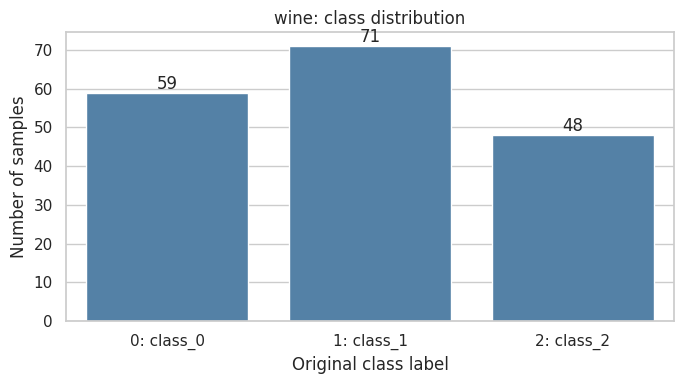

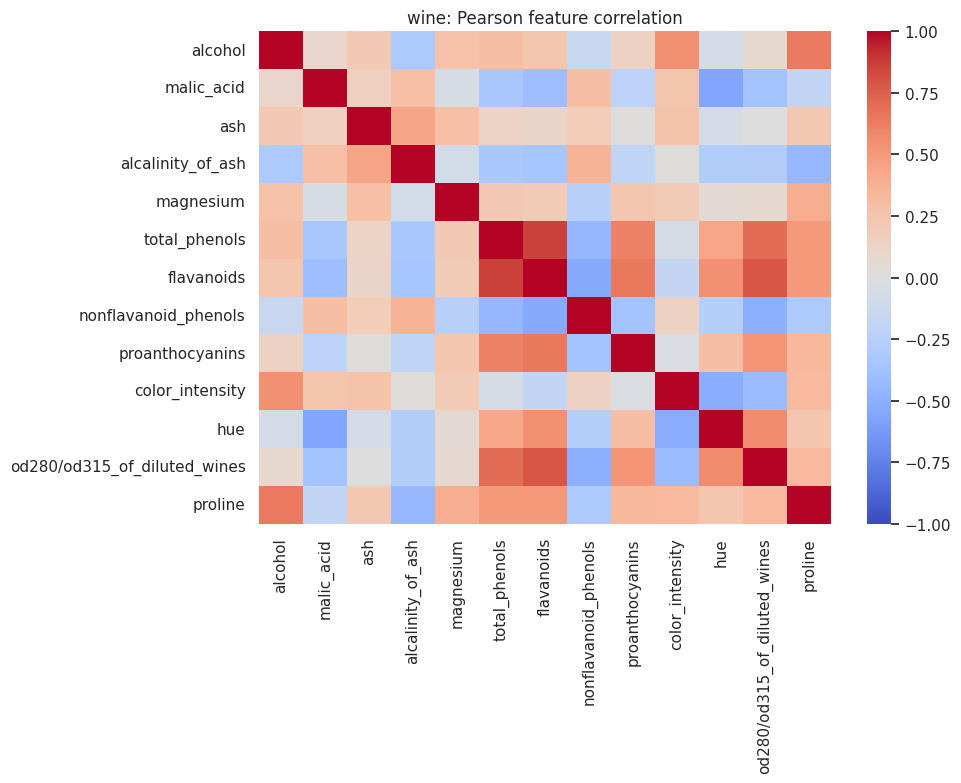

Three strongest UNIQUE feature pairs (no diagonal/mirrors):
  total_phenols / flavanoids: r=0.8646
  flavanoids / od280/od315_of_diluted_wines: r=0.7872
  total_phenols / od280/od315_of_diluted_wines: r=0.6999
Interpretation: Strong absolute Pearson correlations show redundant linear information, not causality. Class counts indicate whether accuracy alone could conceal minority-class errors.


In [6]:

fig,ax=plt.subplots(figsize=(7,4)); counts=y.value_counts().sort_index()
sns.barplot(x=[f'{i}: {LABEL_MAP[i]}' for i in counts.index],y=counts.values,ax=ax,color='steelblue')
ax.set(xlabel='Original class label',ylabel='Number of samples',title=f'{DATASET}: class distribution')
for i,v in enumerate(counts.values): ax.text(i,v,str(v),ha='center',va='bottom')
savefig('class_distribution')
corr=X.corr(method='pearson')
fig,ax=plt.subplots(figsize=(max(10,len(X.columns)*.45),max(8,len(X.columns)*.40)))
sns.heatmap(corr,cmap='coolwarm',center=0,vmin=-1,vmax=1,ax=ax)
ax.set_title(f'{DATASET}: Pearson feature correlation'); savefig('correlation_heatmap')
pairs=[]
for i in range(len(corr.columns)):
    for j in range(i+1,len(corr.columns)):
        pairs.append((corr.columns[i],corr.columns[j],corr.iloc[i,j]))
strongest=sorted(pairs,key=lambda p:abs(p[2]),reverse=True)[:3]
print('Three strongest UNIQUE feature pairs (no diagonal/mirrors):')
for a,b,r in strongest: print(f'  {a} / {b}: r={r:.4f}')
interpret('Strong absolute Pearson correlations show redundant linear information, not causality. Class counts indicate whether accuracy alone could conceal minority-class errors.')


## 6. Feature Boxplots

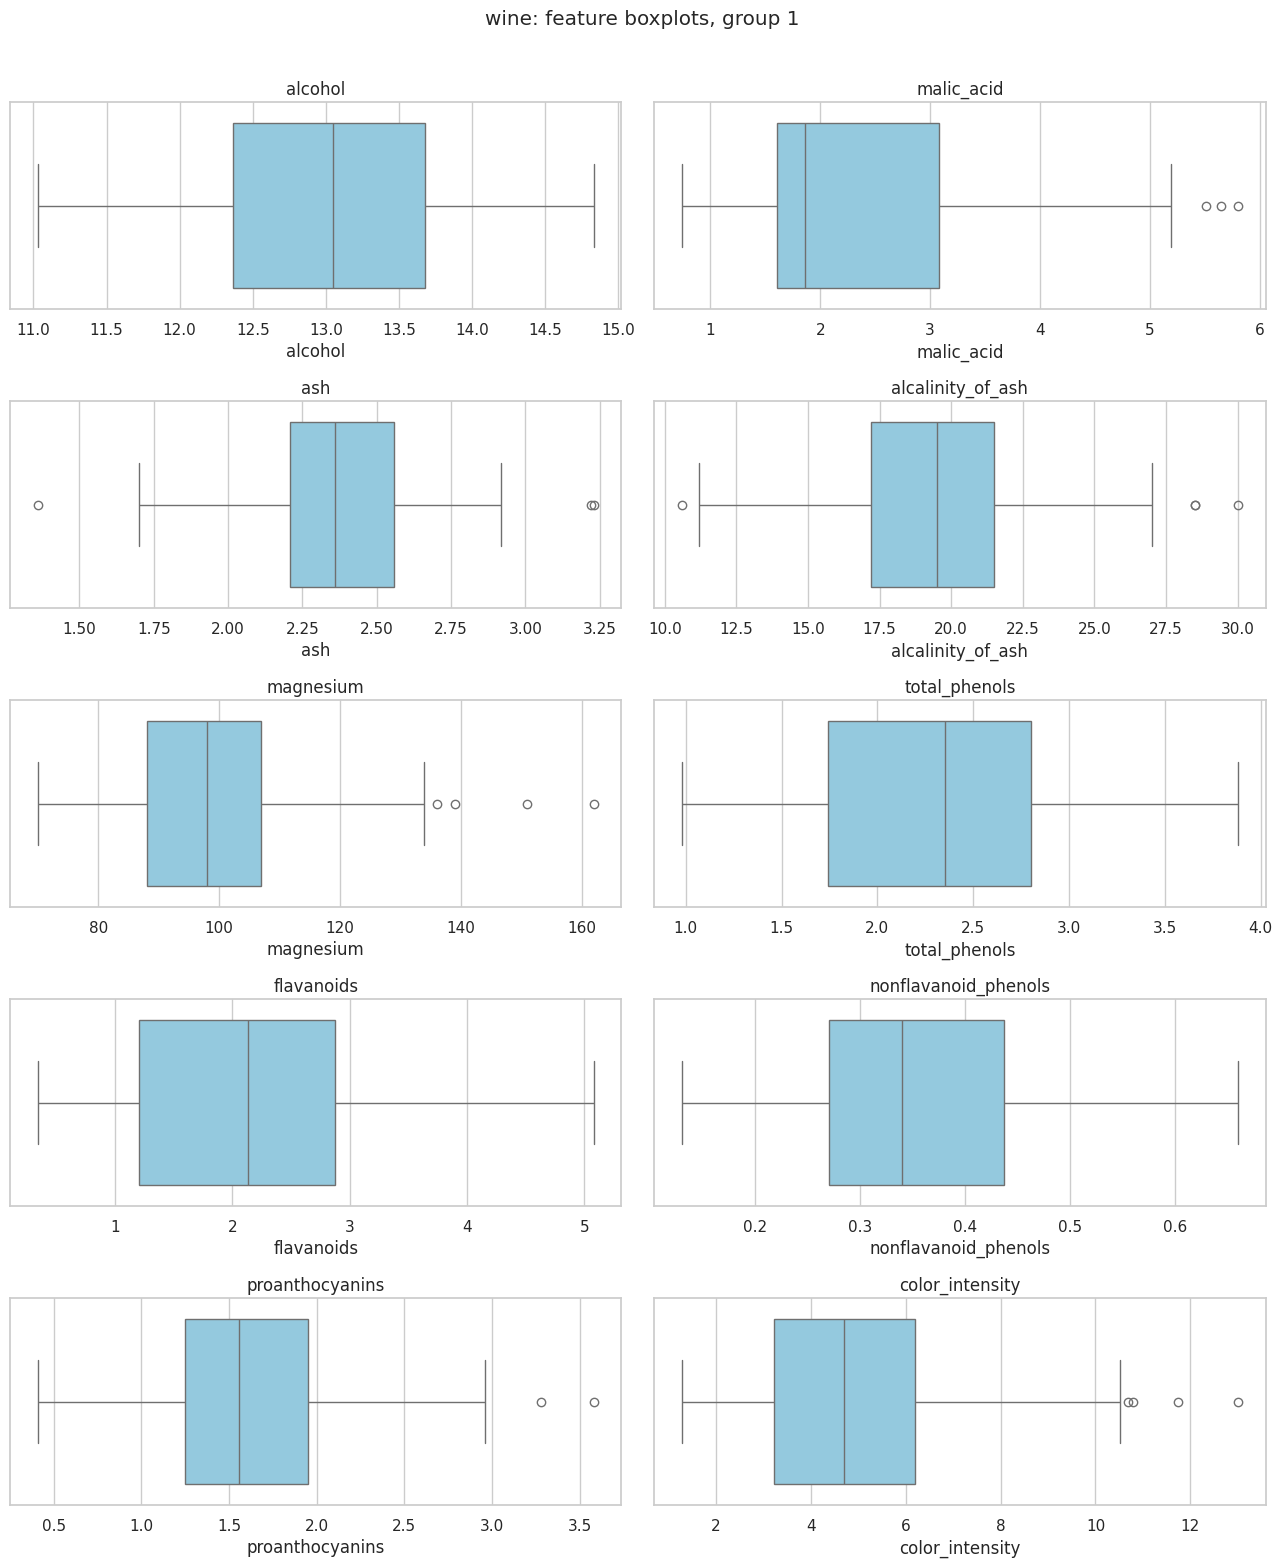

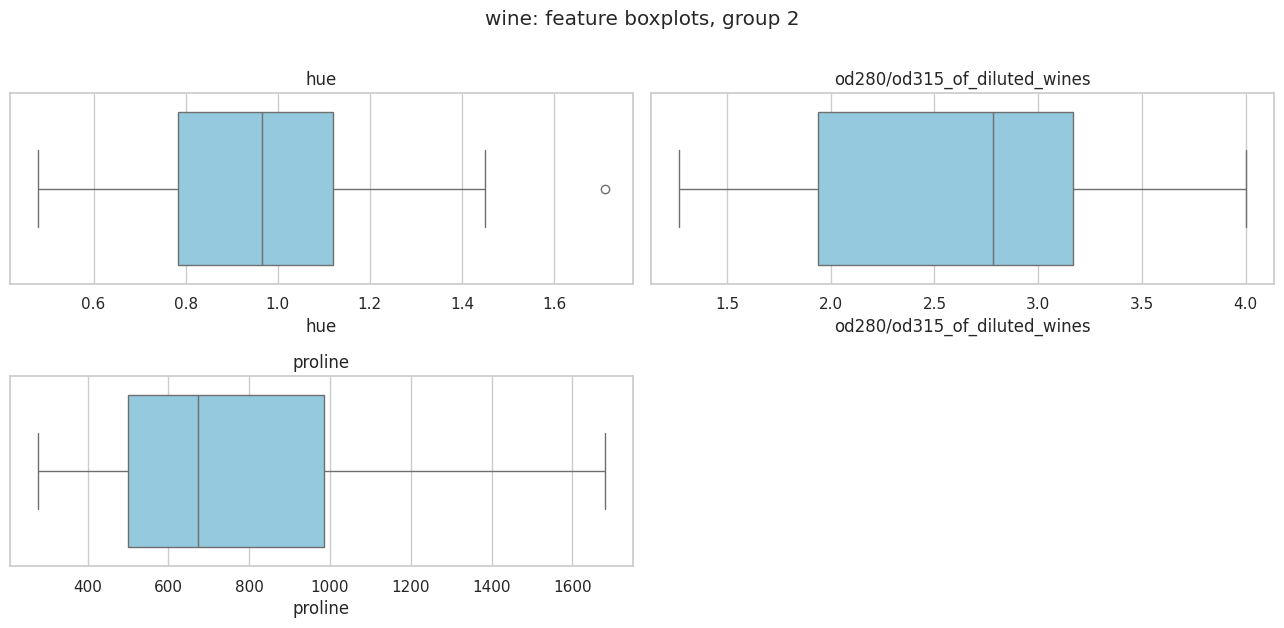

Observation 1: Widest raw ranges: {'proline': 1402.0, 'magnesium': 92.0, 'alcalinity_of_ash': 19.4}
Observation 2: Most IQR-flagged features: {'magnesium': {'IQR_flagged_count': 4}, 'alcalinity_of_ash': {'IQR_flagged_count': 4}, 'color_intensity': {'IQR_flagged_count': 4}}
Interpretation: Boxplots use independent scales for readability. Several features have differing ranges and IQR-flagged tails; these are retained for modeling.


In [7]:

# Grouped figures, all original features retained; independent axes reveal per-feature outliers.
for group_no, start in enumerate(range(0,X.shape[1],10),start=1):
    cols=list(X.columns[start:start+10]); n=len(cols)
    fig,axes=plt.subplots((n+1)//2,2,figsize=(13,3.1*((n+1)//2)))
    axes=np.array(axes).reshape(-1)
    for ax,col in zip(axes,cols): sns.boxplot(x=X[col],ax=ax,color='skyblue'); ax.set_title(col)
    for ax in axes[n:]: ax.axis('off')
    fig.suptitle(f'{DATASET}: feature boxplots, group {group_no}',y=1.01)
    savefig(f'boxplots_{group_no}')
print('Observation 1: Widest raw ranges:',(X.max()-X.min()).sort_values(ascending=False).head(3).to_dict())
print('Observation 2: Most IQR-flagged features:',outlier_counts.head(3).T.to_dict())
interpret('Boxplots use independent scales for readability. Several features have differing ranges and IQR-flagged tails; these are retained for modeling.')


## 7. Fixed Test Split and Three Seed-Based Train/Validation Splits

In [8]:

X_rem,X_test,y_rem,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=42)
splits={}
for seed in SEEDS:
    X_train,X_val,y_train,y_val=train_test_split(X_rem,y_rem,test_size=.125,stratify=y_rem,random_state=seed)
    scaler=StandardScaler().fit(X_train)
    splits[seed]={'X_train':X_train,'X_val':X_val,'y_train':y_train,'y_val':y_val,
                  'raw_train':X_train,'raw_val':X_val,
                  'scaled_train':pd.DataFrame(scaler.transform(X_train),columns=X.columns,index=X_train.index),
                  'scaled_val':pd.DataFrame(scaler.transform(X_val),columns=X.columns,index=X_val.index),
                  'scaler':scaler}
    print(f'Seed {seed}: train={len(X_train)}, validation={len(X_val)}, fixed test={len(X_test)}; overlap=',len(set(X_train.index)&set(X_test.index)))
assert all(set(s['X_train'].index).isdisjoint(X_test.index) and set(s['X_val'].index).isdisjoint(X_test.index) for s in splits.values())
assert len(set(X_test.index))==len(X_test)
interpret('One stratified 20% test set remains fixed. Seeds change only the 70% training / 10% validation membership. Each scaler is fit only to its own training fold.')


Seed 42: train=124, validation=18, fixed test=36; overlap= 0
Seed 52: train=124, validation=18, fixed test=36; overlap= 0
Seed 62: train=124, validation=18, fixed test=36; overlap= 0
Interpretation: One stratified 20% test set remains fixed. Seeds change only the 70% training / 10% validation membership. Each scaler is fit only to its own training fold.


## 8. Classification: 66 Validation Fits, Metrics and Undefined Classes

In [9]:

def make_classifier(family,param,seed):
    if family=='Decision Tree': return DecisionTreeClassifier(max_depth=param,random_state=seed)
    if family=='KNN': return KNeighborsClassifier(n_neighbors=param,weights='uniform',metric='euclidean')
    return GaussianNB()
def undefined_classes(y_true,y_pred,labels):
    # Undefined precision when no predicted instances; undefined recall when no actual instances.
    return {'precision':[int(c) for c in labels if np.sum(y_pred==c)==0],
            'recall':[int(c) for c in labels if np.sum(y_true==c)==0]}
def evaluate(model,features,labels):
    pred=model.predict(features)
    proba=model.predict_proba(features)
    assert np.array_equal(model.classes_,CLASS_IDS), 'Probability columns do not match original class IDs'
    if DATASET=='breast_cancer':
        binary=(np.asarray(labels)==0).astype(int)
        auc=roc_auc_score(binary,proba[:,list(model.classes_).index(0)])
    else:
        auc=roc_auc_score(labels,proba,multi_class='ovr',average='macro',labels=model.classes_)
    return {'accuracy':accuracy_score(labels,pred),
            'macro_precision':precision_score(labels,pred,average='macro',zero_division=0),
            'macro_recall':recall_score(labels,pred,average='macro',zero_division=0),
            'macro_f1':f1_score(labels,pred,average='macro',zero_division=0),
            'roc_auc':auc,'undefined':undefined_classes(np.asarray(labels),pred,CLASS_IDS)}
records=[]
for seed in SEEDS:
    s=splits[seed]
    for representation in ['raw','scaled']:
        tr=s[f'{representation}_train']; va=s[f'{representation}_val']
        for family,parameters in [('Decision Tree',[2,3,5,10,None]),('KNN',[1,3,5,7,11]),('GaussianNB',['default'])]:
            for param in parameters:
                model=make_classifier(family,param,seed)
                model.fit(tr,s['y_train'])
                train_f1=f1_score(s['y_train'],model.predict(tr),average='macro',zero_division=0)
                metrics=evaluate(model,va,s['y_val'])
                records.append({'seed':seed,'representation':representation,'model':family,'parameter':str(param),
                                'train_macro_f1':train_f1,**metrics})
runs=pd.DataFrame(records)
assert len(runs)==66
runs['undefined_precision_classes']=runs['undefined'].map(lambda d:str(d['precision']))
runs['undefined_recall_classes']=runs['undefined'].map(lambda d:str(d['recall']))
runs=runs.drop(columns=['undefined'])
display(runs)
runs.to_csv(f'{DATASET}_classification_66_runs.csv',index=False)
print('Undefined precision instances:',runs[runs.undefined_precision_classes!='[]'][['seed','model','parameter','undefined_precision_classes']].to_string(index=False) or 'none')
print('Undefined recall instances:',runs[runs.undefined_recall_classes!='[]'][['seed','model','parameter','undefined_recall_classes']].to_string(index=False) or 'none')
interpret('All metrics are computed on each run’s own validation subset; macro scores weight classes equally. AUC uses probabilities in original class order, not hard labels.')


,seed,representation,model,parameter,train_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,roc_auc,undefined_precision_classes,undefined_recall_classes
0,42,raw,Decision Tree,2,0.929694,0.833333,0.863095,0.811111,0.817521,0.910596,[],[]
1,42,raw,Decision Tree,3,0.992584,0.944444,0.958333,0.944444,0.947475,0.968645,[],[]
2,42,raw,Decision Tree,5,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,[],[]
3,42,raw,Decision Tree,10,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,[],[]
4,42,raw,Decision Tree,None,1.000000,0.944444,0.958333,0.944444,0.947475,0.957071,[],[]
...,...,...,...,...,...,...,...,...,...,...,...,...
61,62,scaled,KNN,3,0.960888,0.888889,0.896825,0.904762,0.888500,1.000000,[],[]
62,62,scaled,KNN,5,0.975871,0.944444,0.944444,0.952381,0.944056,1.000000,[],[]
63,62,scaled,KNN,7,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000,[],[]
64,62,scaled,KNN,11,0.968371,0.944444,0.944444,0.952381,0.944056,1.000000,[],[]


Undefined precision instances: Empty DataFrame
Columns: [seed, model, parameter, undefined_precision_classes]
Index: []
Undefined recall instances: Empty DataFrame
Columns: [seed, model, parameter, undefined_recall_classes]
Index: []
Interpretation: All metrics are computed on each run’s own validation subset; macro scores weight classes equally. AUC uses probabilities in original class order, not hard labels.


## 9. Classification: 22-Row Mean/SD Summary and Configuration Selection

In [10]:

metric_cols=['accuracy','macro_precision','macro_recall','macro_f1','roc_auc','train_macro_f1']
summary=runs.groupby(['representation','model','parameter'],sort=False)[metric_cols].agg(['mean','std'])
summary.columns=[f'{metric}_{stat}' for metric,stat in summary.columns]
summary=summary.reset_index()
assert len(summary)==22
display(summary)
summary.to_csv(f'{DATASET}_classification_22_summary.csv',index=False)
# Select using validation macro F1 only; deterministic tie-breaker by AUC, then listed order.
selected=summary.sort_values(['macro_f1_mean','roc_auc_mean'],ascending=[False,False],kind='stable').iloc[0]
print('SELECTED:',selected[['model','parameter','representation','macro_f1_mean','macro_f1_std','roc_auc_mean']].to_dict())
interpret('Selection uses three-seed mean validation macro F1, with mean validation AUC as a tie-breaker. The fixed test set is untouched during selection.')


,representation,model,parameter,accuracy_mean,accuracy_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,macro_f1_mean,macro_f1_std,roc_auc_mean,roc_auc_std,train_macro_f1_mean,train_macro_f1_std
0,raw,Decision Tree,2,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898,0.936466,0.010609
1,raw,Decision Tree,3,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103,0.992584,0.000000
2,raw,Decision Tree,5,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735,1.000000,0.000000
3,raw,Decision Tree,10,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735,1.000000,0.000000
4,raw,Decision Tree,None,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735,1.000000,0.000000
5,raw,KNN,1,0.703704,0.032075,0.688624,0.023943,0.683598,0.022298,0.671386,0.022592,0.765361,0.018120,1.000000,0.000000
6,raw,KNN,3,0.666667,0.055556,0.661376,0.049616,0.651852,0.047839,0.645573,0.042877,0.833286,0.031092,0.829374,0.013389
7,raw,KNN,5,0.703704,0.032075,0.728042,0.072202,0.686243,0.029369,0.666707,0.039943,0.864473,0.011514,0.773922,0.009106
8,raw,KNN,7,0.666667,0.000000,0.647090,0.022523,0.654497,0.015252,0.635589,0.031621,0.845858,0.008446,0.780410,0.023097
9,raw,KNN,11,0.629630,0.032075,0.614815,0.012731,0.613757,0.021078,0.600477,0.000964,0.821627,0.025415,0.730922,0.008258


SELECTED: {'model': 'KNN', 'parameter': '5', 'representation': 'scaled', 'macro_f1_mean': 0.9813519813519814, 'macro_f1_std': 0.032299315758860164, 'roc_auc_mean': 1.0}
Interpretation: Selection uses three-seed mean validation macro F1, with mean validation AUC as a tie-breaker. The fixed test set is untouched during selection.


## 10. Tree Depth and KNN Neighbor Comparison Figures

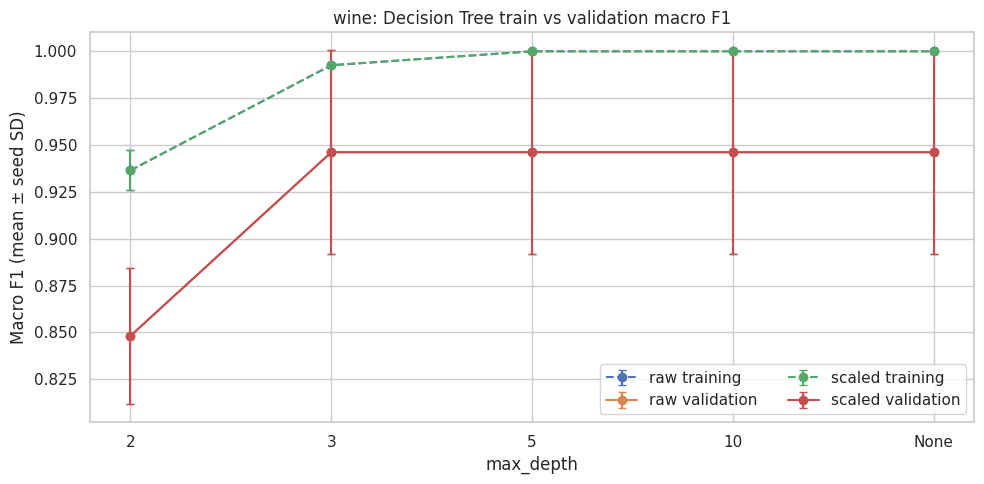

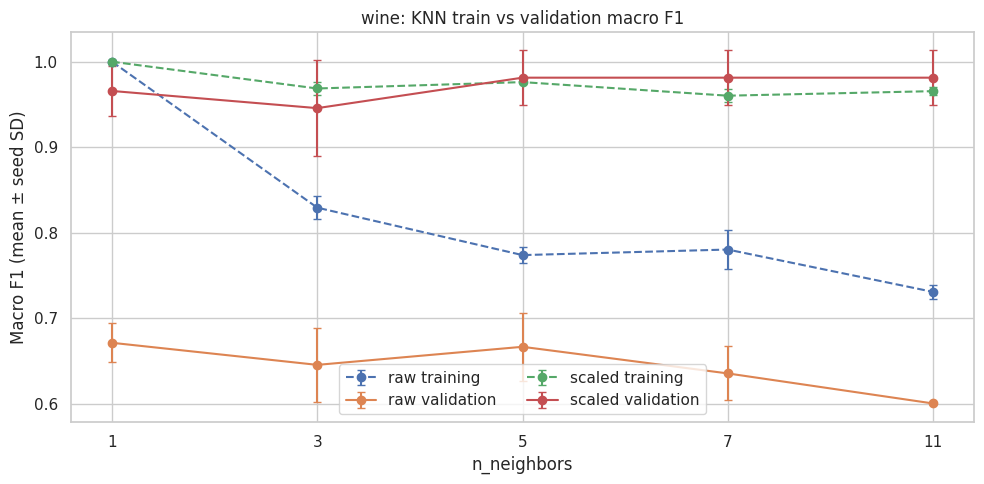

Interpretation: Large training-validation gaps may indicate overfitting; error bars show variation across the three train/validation seeds.


In [11]:

for family,parameters,filename,xlabel in [('Decision Tree',['2','3','5','10','None'],'tree_depth','max_depth'),
                                           ('KNN',['1','3','5','7','11'],'knn_neighbors','n_neighbors')]:
    fig,ax=plt.subplots(figsize=(10,5))
    for rep in ['raw','scaled']:
        sub=summary[(summary.model==family)&(summary.representation==rep)].set_index('parameter').loc[parameters]
        xx=np.arange(len(parameters))
        for metric,style in [('train_macro_f1','--'),('macro_f1','-')]:
            ax.errorbar(xx,sub[f'{metric}_mean'],yerr=sub[f'{metric}_std'].fillna(0),
                        marker='o',linestyle=style,capsize=3,label=f'{rep} {"training" if metric=="train_macro_f1" else "validation"}')
    ax.set_xticks(np.arange(len(parameters)),parameters)
    ax.set(xlabel=xlabel,ylabel='Macro F1 (mean ± seed SD)',title=f'{DATASET}: {family} train vs validation macro F1')
    ax.legend(ncol=2); savefig(filename)
interpret('Large training-validation gaps may indicate overfitting; error bars show variation across the three train/validation seeds.')


## 11. Final Classifier: Fixed-Test Confusion Matrix, ROC and Manual Metrics

FINAL TEST METRICS: {'accuracy': 0.9722222222222222, 'macro_precision': 0.9696969696969697, 'macro_recall': 0.9761904761904763, 'macro_f1': 0.9717813051146384, 'roc_auc': 0.9988178488178487, 'undefined': {'precision': [], 'recall': []}}


,precision,recall,f1-score,support
class_0,1.000000,1.000000,1.000000,12.000000
class_1,1.000000,0.928571,0.962963,14.000000
class_2,0.909091,1.000000,0.952381,10.000000
accuracy,0.972222,0.972222,0.972222,0.972222
macro avg,0.969697,0.976190,0.971781,36.000000
weighted avg,0.974747,0.972222,0.972369,36.000000


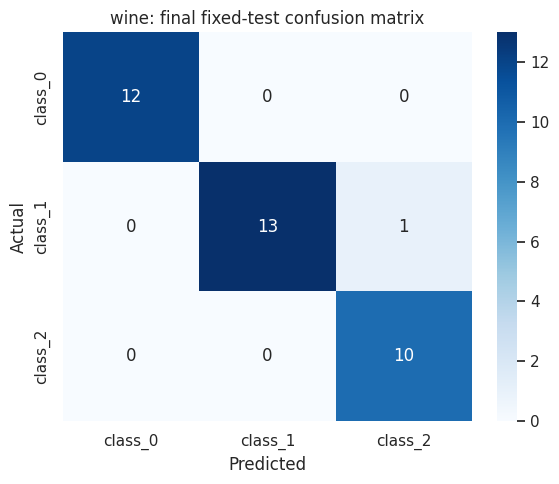

Largest wine confusion: actual class 1 (class_1) predicted as 2 (class_2): 1 samples.
Manual one-vs-rest metrics for class_0 : {'TP': np.int64(12), 'FP': np.int64(0), 'FN': np.int64(0), 'precision': np.float64(1.0), 'recall': np.float64(1.0), 'f1': np.float64(1.0)}
Classification report SAME CLASS: {'precision': 1.0, 'recall': 1.0, 'f1-score': 1.0}
Wine macro OVR AUC: 0.9988178488178487


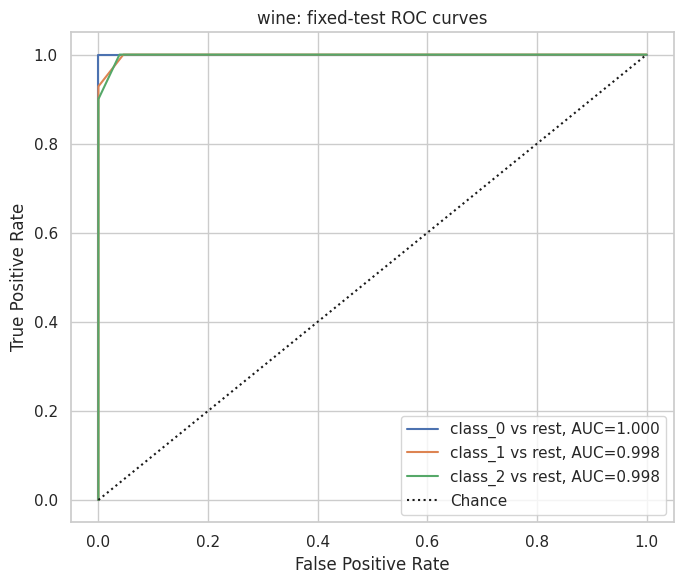

Interpretation: The test confusion matrix uses original label order. Manual per-class precision/recall/F1 are compared to that class in the classification report, not to macro averages.


In [12]:

# Final evaluation uses the selected configuration on seed-42 training rows only.
# The fixed test set was never used to choose hyperparameters or fit the scaler.
rep=selected['representation']; family=selected['model']; p=selected['parameter']
param=None if p=='None' else ('default' if p=='default' else int(p))
s42=splits[42]
final_train=s42[f'{rep}_train']
final_test=pd.DataFrame(s42['scaler'].transform(X_test),columns=X.columns,index=X_test.index) if rep=='scaled' else X_test
final_model=make_classifier(family,param,42).fit(final_train,s42["y_train"])
test_pred=final_model.predict(final_test)
test_probs=final_model.predict_proba(final_test)
assert np.array_equal(final_model.classes_,CLASS_IDS)
print('FINAL TEST METRICS:',evaluate(final_model,final_test,y_test))
report=classification_report(y_test,test_pred,labels=CLASS_IDS,target_names=CLASS_NAMES,output_dict=True,zero_division=0)
display(pd.DataFrame(report).T)
cm=confusion_matrix(y_test,test_pred,labels=CLASS_IDS)
fig,ax=plt.subplots(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax)
ax.set(xlabel='Predicted',ylabel='Actual',title=f'{DATASET}: final fixed-test confusion matrix')
savefig('final_confusion_matrix')
if DATASET=='breast_cancer':
    TP, FN, FP, TN=cm[0,0],cm[0,1],cm[1,0],cm[1,1]
    print(f'Malignant-positive counts: TP={TP}, FN={FN}, FP={FP}, TN={TN}')
    chosen_class=0
else:
    chosen_class=0
    offdiag=cm.copy(); np.fill_diagonal(offdiag,0)
    if offdiag.max()==0: print('Wine: no off-diagonal errors in the test confusion matrix.')
    else:
        i,j=np.unravel_index(np.argmax(offdiag),offdiag.shape)
        print(f'Largest wine confusion: actual class {CLASS_IDS[i]} ({CLASS_NAMES[i]}) predicted as {CLASS_IDS[j]} ({CLASS_NAMES[j]}): {offdiag[i,j]} samples.')
idx=list(CLASS_IDS).index(chosen_class)
tp=cm[idx,idx]; fp=cm[:,idx].sum()-tp; fn=cm[idx,:].sum()-tp
p_manual=tp/(tp+fp) if tp+fp else np.nan
r_manual=tp/(tp+fn) if tp+fn else np.nan
f_manual=2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan
print('Manual one-vs-rest metrics for',CLASS_NAMES[idx],':',{'TP':tp,'FP':fp,'FN':fn,'precision':p_manual,'recall':r_manual,'f1':f_manual})
print('Classification report SAME CLASS:',{k:report[CLASS_NAMES[idx]][k] for k in ['precision','recall','f1-score']})
if np.isnan(p_manual) or np.isnan(r_manual) or np.isnan(f_manual): print('At least one manual metric is undefined due to a zero denominator; report substitutes zero.')
else:
    assert np.allclose([p_manual,r_manual,f_manual],[report[CLASS_NAMES[idx]][k] for k in ['precision','recall','f1-score']])
fig,ax=plt.subplots(figsize=(7,6))
if DATASET=='breast_cancer':
    yy=(y_test.to_numpy()==0).astype(int)
    scores=test_probs[:,list(final_model.classes_).index(0)]
    fpr,tpr,_=roc_curve(yy,scores)
    auc=roc_auc_score(yy,scores)
    ax.plot(fpr,tpr,label=f'Malignant (original class 0), AUC={auc:.3f}')
else:
    for i,c in enumerate(CLASS_IDS):
        yy=(y_test.to_numpy()==c).astype(int)
        fpr,tpr,_=roc_curve(yy,test_probs[:,i]); area=roc_auc_score(yy,test_probs[:,i])
        ax.plot(fpr,tpr,label=f'{CLASS_NAMES[i]} vs rest, AUC={area:.3f}')
    print('Wine macro OVR AUC:',roc_auc_score(y_test,test_probs,multi_class='ovr',average='macro',labels=CLASS_IDS))
ax.plot([0,1],[0,1],'k:',label='Chance')
ax.set(xlabel='False Positive Rate',ylabel='True Positive Rate',title=f'{DATASET}: fixed-test ROC curves')
ax.legend(); savefig('final_roc')
interpret('The test confusion matrix uses original label order. Manual per-class precision/recall/F1 are compared to that class in the classification report, not to macro averages.')


## 12. K-Means: Six Fits, Validation ARI and Silhouette

In [13]:

cluster_records=[]
for seed in SEEDS:
    s=splits[seed]
    for rep in ['raw','scaled']:
        tr=s[f'{rep}_train']; va=s[f'{rep}_val']
        km=KMeans(n_clusters=len(CLASS_IDS),random_state=seed,n_init=10)
        km.fit(tr) # no target labels passed
        clusters=km.predict(va)
        silhouette=silhouette_score(va,clusters) if 1<len(np.unique(clusters))<len(va) else np.nan
        cluster_records.append({'seed':seed,'representation':rep,'train_inertia':km.inertia_,
                                'validation_ARI':adjusted_rand_score(s['y_val'],clusters),
                                'validation_silhouette':silhouette,'validation_clusters':len(np.unique(clusters))})
cluster_runs=pd.DataFrame(cluster_records)
assert len(cluster_runs)==6
display(cluster_runs)
cluster_runs.to_csv(f'{DATASET}_kmeans_6_runs.csv',index=False)
cluster_summary=cluster_runs.groupby('representation',sort=False)[['train_inertia','validation_ARI','validation_silhouette']].agg(['mean','std'])
cluster_summary.columns=[f'{m}_{stat}' for m,stat in cluster_summary.columns]
cluster_summary=cluster_summary.reset_index()
assert len(cluster_summary)==2
display(cluster_summary)
cluster_summary.to_csv(f'{DATASET}_kmeans_2_summary.csv',index=False)
interpret('K-Means cluster IDs are arbitrary, not class predictions. ARI compares partitions label-invariantly; silhouette uses predicted validation clusters. Raw versus scaled inertia has different units and should not be compared directly.')


,seed,representation,train_inertia,validation_ARI,validation_silhouette,validation_clusters
0,42,raw,1.350496e+06,0.282836,0.486994,3
1,42,scaled,8.747391e+02,1.000000,0.251637,3
2,52,raw,1.303675e+06,0.400588,0.555887,3
3,52,scaled,8.904355e+02,1.000000,0.301008,3
4,62,raw,1.390754e+06,0.400588,0.686671,3
5,62,scaled,8.722466e+02,1.000000,0.272587,3


,representation,train_inertia_mean,train_inertia_std,validation_ARI_mean,validation_ARI_std,validation_silhouette_mean,validation_silhouette_std
0,raw,1.348308e+06,43580.909759,0.361337,0.067984,0.576517,0.101425
1,scaled,8.791404e+02,9.860948,1.000000,0.000000,0.275077,0.024780


Interpretation: K-Means cluster IDs are arbitrary, not class predictions. ARI compares partitions label-invariantly; silhouette uses predicted validation clusters. Raw versus scaled inertia has different units and should not be compared directly.


## 13. K-Means Class-versus-Cluster Two-Panel Figures

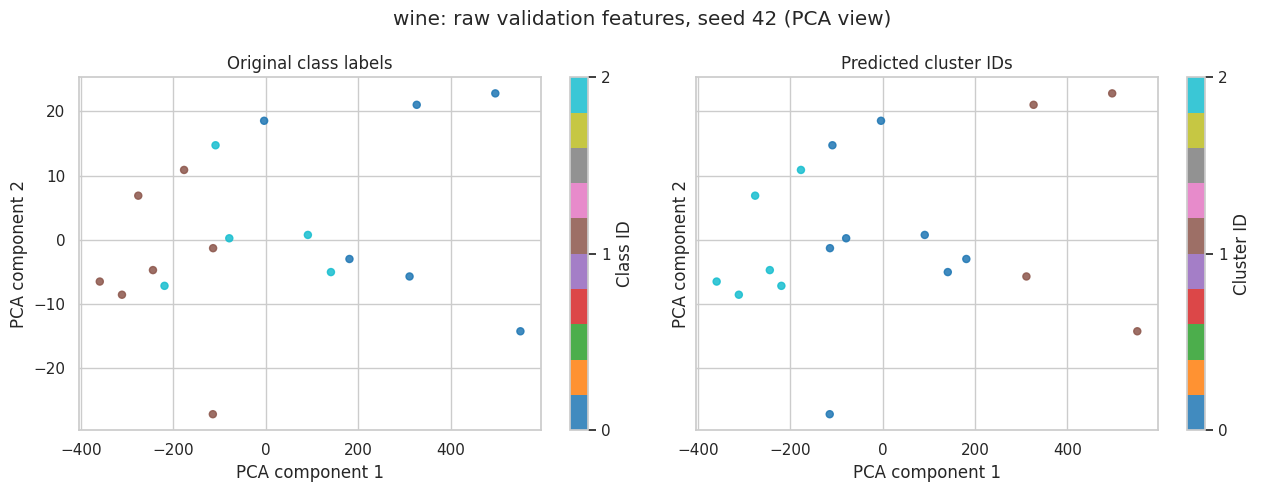

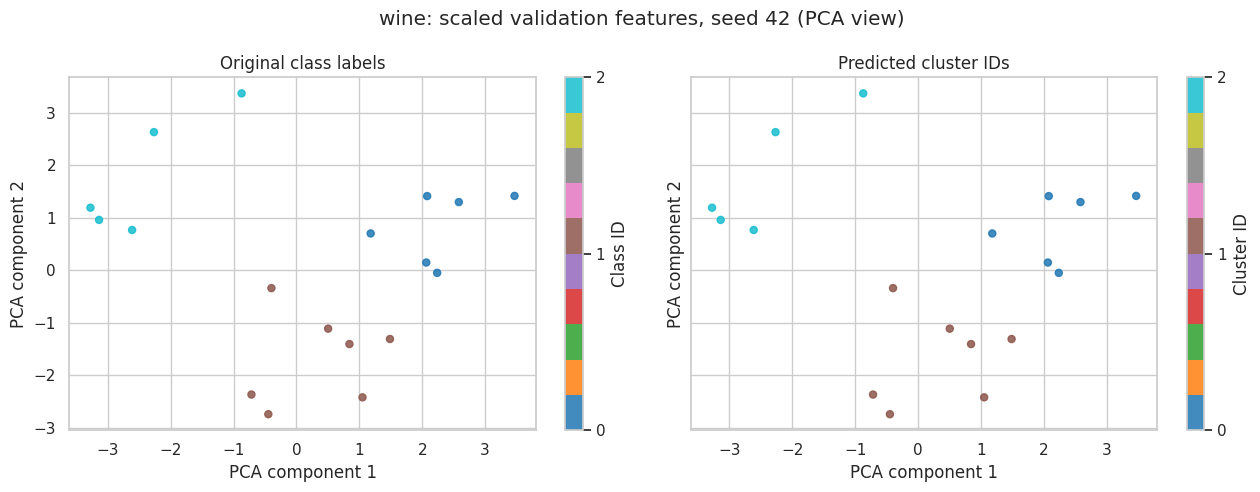

Interpretation: Both panels show identical validation observations projected using PCA fitted on training features. Matching colors between panels do not imply matching label IDs.


In [14]:

# Visual evidence uses seed 42 only; all three seeds are already in the run table.
seed=42;s=splits[seed]
for rep in ['raw','scaled']:
    tr=s[f'{rep}_train']; va=s[f'{rep}_val']
    km=KMeans(n_clusters=len(CLASS_IDS),random_state=seed,n_init=10).fit(tr)
    clusters=km.predict(va)
    pca=PCA(n_components=2).fit(tr)
    coords=pca.transform(va)
    fig,axes=plt.subplots(1,2,figsize=(13,5),sharex=True,sharey=True)
    for ax,colors,ttl in [(axes[0],s['y_val'].to_numpy(),'Original class labels'),(axes[1],clusters,'Predicted cluster IDs')]:
        scatter=ax.scatter(coords[:,0],coords[:,1],c=colors,cmap='tab10',s=26,alpha=.85)
        ax.set(title=ttl,xlabel='PCA component 1',ylabel='PCA component 2')
        fig.colorbar(scatter,ax=ax,label='Class ID' if ax==axes[0] else 'Cluster ID',ticks=range(len(CLASS_IDS)))
    fig.suptitle(f'{DATASET}: {rep} validation features, seed 42 (PCA view)')
    savefig(f'kmeans_{rep}_two_panel')
interpret('Both panels show identical validation observations projected using PCA fitted on training features. Matching colors between panels do not imply matching label IDs.')


## 14. Experiment Integrity and Deliverables

In [15]:

print('Classification fits:',len(runs),'K-Means fits:',len(cluster_runs),'total fits for this dataset:',len(runs)+len(cluster_runs))
print('Classification summary rows:',len(summary),'K-Means summary rows:',len(cluster_summary))
print('Figure files for this dataset:',len(list(OUT.glob(f'{DATASET}_*.png'))))
print('Test row indices (fixed):',X_test.index.tolist())
assert len(runs)+len(cluster_runs)==72
interpret('Across both notebooks the assignment totals 132 classifier fits and 12 K-Means fits = 144; additional final refits and figure-only K-Means refits are reporting operations, not counted among the specified experimental runs.')


Classification fits: 66 K-Means fits: 6 total fits for this dataset: 72
Classification summary rows: 22 K-Means summary rows: 2
Figure files for this dataset: 10
Test row indices (fixed): [10, 134, 28, 121, 62, 51, 7, 66, 129, 166, 102, 143, 42, 130, 14, 108, 105, 20, 100, 38, 93, 60, 22, 18, 98, 64, 58, 132, 112, 155, 48, 176, 94, 177, 164, 173]
Interpretation: Across both notebooks the assignment totals 132 classifier fits and 12 K-Means fits = 144; additional final refits and figure-only K-Means refits are reporting operations, not counted among the specified experimental runs.
